In [2]:
from google.colab import files
uploaded = files.upload()

Saving dataset_base.csv to dataset_base.csv
Saving dataset_with_technicals.csv to dataset_with_technicals.csv


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers, regularizers
from sklearn.preprocessing import StandardScaler
from utils import load_split, evaluate

print(keras.__version__)

paths = {"base": "dataset_base.csv", "tech": "dataset_with_technicals.csv"}

3.13.2


In [4]:
def prep(path):
    X_tr, X_te, y_tr, y_te = load_split(path)
    n_val = int(len(X_tr) * 0.15)
    X_sub, X_val = X_tr.iloc[:-n_val], X_tr.iloc[-n_val:]
    y_sub, y_val = y_tr.iloc[:-n_val], y_tr.iloc[-n_val:]

    sc = StandardScaler().fit(X_sub)
    y_mu, y_sd = y_sub.mean(), y_sub.std()
    return dict(
        Xs=sc.transform(X_sub), ys=((y_sub - y_mu) / y_sd).values,
        Xv=sc.transform(X_val), yv=((y_val - y_mu) / y_sd).values,
        Xt=sc.transform(X_te),
        y_val=y_val.values, y_te=y_te, y_tr_mean=y_tr.mean(),
        y_mu=y_mu, y_sd=y_sd, index=y_te.index,
    )


def build(n_features, units, dropout, l2, lr):
    model = keras.Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(units[0], activation="relu", kernel_regularizer=regularizers.l2(l2)),
        layers.Dropout(dropout),
        layers.Dense(units[1], activation="relu", kernel_regularizer=regularizers.l2(l2)),
        layers.Dropout(dropout),
        layers.Dense(1),
    ])
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="mse")
    return model

In [5]:
configs = {
    "small":  dict(units=(16, 8),  dropout=0.3, l2=1e-2, lr=1e-3),
    "medium": dict(units=(32, 16), dropout=0.3, l2=1e-3, lr=1e-3),
    "large":  dict(units=(64, 32), dropout=0.5, l2=1e-3, lr=5e-4),
}
SEEDS = range(5)


def fit_config(d, cfg):
    val_preds, te_preds, last_hist = [], [], None
    for s in SEEDS:
        keras.utils.set_random_seed(s)
        m = build(d["Xs"].shape[1], **cfg)
        h = m.fit(
            d["Xs"], d["ys"],
            validation_data=(d["Xv"], d["yv"]),
            epochs=300, batch_size=32, verbose=0,
            callbacks=[keras.callbacks.EarlyStopping(
                monitor="val_loss", patience=20, restore_best_weights=True)],
        )
        val_preds.append(m.predict(d["Xv"], verbose=0).ravel() * d["y_sd"] + d["y_mu"])
        te_preds.append(m.predict(d["Xt"], verbose=0).ravel() * d["y_sd"] + d["y_mu"])
        last_hist = h.history
    return np.mean(val_preds, axis=0), np.mean(te_preds, axis=0), last_hist


results, store = [], {}

for k, p in paths.items():
    d = prep(p)
    best = None
    for name, cfg in configs.items():
        vp, tp, hist = fit_config(d, cfg)
        val_rmse = np.sqrt(np.mean((d["y_val"] - vp) ** 2))
        print(f"[{k}] {name:<7} val RMSE = {val_rmse:.4f}", flush=True)
        if best is None or val_rmse < best[0]:
            best = (val_rmse, name, tp, hist)

    _, name, tp, hist = best
    print(f"[{k}] chosen config: {name}")
    store[k] = dict(pred=tp, hist=hist, index=d["index"], y_te=d["y_te"])
    results.append({**evaluate(d["y_te"], tp, d["y_tr_mean"], "Keras MLP"), "data": k})

res = pd.DataFrame(results).set_index(["data", "model"])
print(res.round(4))
res.to_csv("keras_results.csv")

[base] small   val RMSE = 0.0395
[base] medium  val RMSE = 0.0388
[base] large   val RMSE = 0.0391
[base] chosen config: medium
[tech] small   val RMSE = 0.0389
[tech] medium  val RMSE = 0.0389
[tech] large   val RMSE = 0.0389
[tech] chosen config: medium
                  RMSE     MAE      R2  R2_OOS  DirAcc
data model                                            
base Keras MLP  0.0366  0.0261  0.0071  0.0083  0.5257
tech Keras MLP  0.0372  0.0266 -0.0186 -0.0176  0.5029


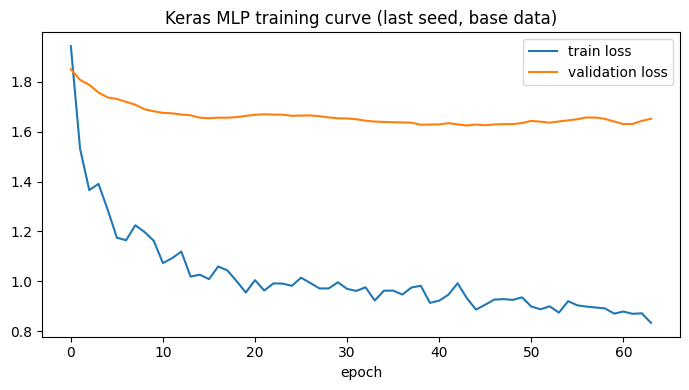

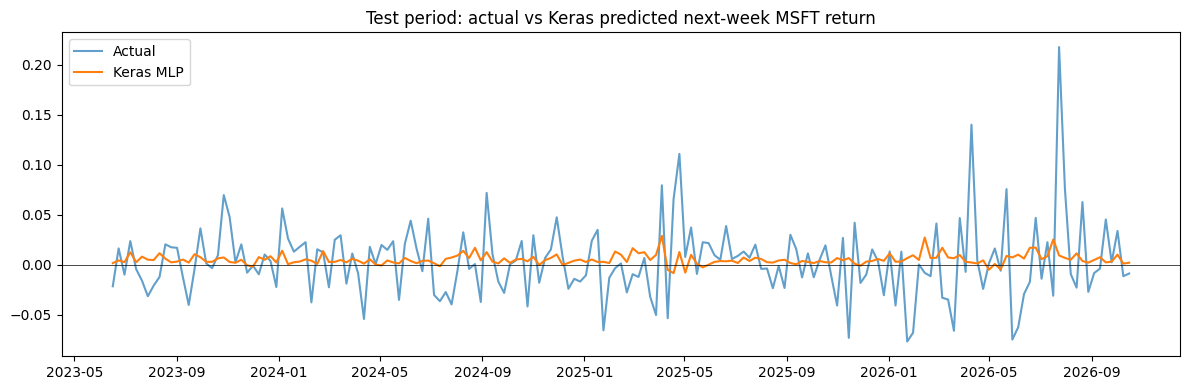

In [6]:
k = "base"

plt.figure(figsize=(7, 4))
plt.plot(store[k]["hist"]["loss"], label="train loss")
plt.plot(store[k]["hist"]["val_loss"], label="validation loss")
plt.title("Keras MLP training curve (last seed, base data)")
plt.xlabel("epoch"); plt.legend(); plt.tight_layout()
plt.savefig("11_keras_loss_curve.png", dpi=150)
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(store[k]["index"], store[k]["y_te"].values, label="Actual", alpha=0.7)
plt.plot(store[k]["index"], store[k]["pred"], label="Keras MLP")
plt.axhline(0, color="k", lw=0.5)
plt.title("Test period: actual vs Keras predicted next-week MSFT return")
plt.legend(); plt.tight_layout()
plt.savefig("12_keras_pred_vs_actual.png", dpi=150)
plt.show()

In [7]:
from google.colab import files
for f in ["keras_results.csv", "11_keras_loss_curve.png", "12_keras_pred_vs_actual.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>